# Estudo Comparativo de Classificação Acústica Submarina — Dataset IARA
### Notebook 28: Auditoria e Correção da Extração HHT

**Resumo.** O cache HHT usado até 23/10/2026 (`data/iara_processed/hht_features/` e `cache_hht.pkl`, extraídos em 15/10) **não** foi gerado com uma configuração única: o script `scratch/extract_all_hht.py` foi editado no meio da extração (2026-10-15 04:55:56), e a extração foi retomada pulando os arquivos já gravados (2026-10-15 03:57:29 a 2026-10-15 05:02:15). As 571 gravações extraídas antes da edição usaram um limite de iterações de peneiramento da EMD de pelo menos 100; as 1135 seguintes, 30. **Nenhuma das 196 gravações BACKGROUND está no primeiro grupo**, que tem 431 dos 1082 navios rotulados: a configuração de extração ficou associada à classe.

O HHT foi re-extraído com uma configuração única (8 IMFs, `MAX_ITERATION=30`, o valor do script atual) e os 22 experimentos HHT foram retreinados. Este notebook documenta a evidência, a correção e o efeito em cada resultado.

> Todos os números são recalculados das predições por janela (`notebooks/iara_results.py`; voto majoritário por arquivo, ACC balanceada, desvio populacional nos 10 folds). **Antes** = `results/trainings/_backup_hht_iter_misto_20261015/<exp>`; **depois** = `results/trainings/multirep/<exp>`. As evidências da extração vêm de `scratch/audit_hht_mixed_extraction.py` (`reports/correcao_hht/`).

In [1]:
import os, sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
try:
    from IPython.display import display
except ImportError:
    display = print

for _p in ('.', 'src', 'notebooks', 'notebooks/src'):
    if os.path.exists(os.path.join(_p, 'iara_results.py')) and os.path.abspath(_p) not in sys.path:
        sys.path.insert(0, os.path.abspath(_p))
import iara_results as R

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams.update({'font.family': 'sans-serif', 'font.size': 11, 'figure.dpi': 120})

AUD = os.path.join(R.ROOT, 'reports', 'correcao_hht')
BACKUP = '_backup_hht_iter_misto_20261015'          # results/trainings/<BACKUP>/<exp> = ANTES
CLS = {0: 'SMALL', 1: 'MEDIUM', 2: 'LARGE', 3: 'BACKGROUND'}

## 1. A evidência

### 1.1 Duas configurações de EMD no mesmo cache
`scratch/audit_hht_mixed_extraction.py` recalculou, com a cadeia de `extract_all_hht.py`, 8 gravações sorteadas de cada grupo (janelas 0, 3, 10, 30) com `MAX_ITERATION` = 30, 100, 1000 e comparou com o espectro antigo. Percentual de janelas reproduzidas **exatamente** (diferença máxima < 1e-6):

| Grupo do arquivo antigo | MAX_ITERATION=30 | MAX_ITERATION=100 | MAX_ITERATION=1000 |
| :--- | :---: | :---: | :---: |
| antes da edição (571 gravações) | 56,2% | 90,6% | 90,6% |
| depois da edição (1135 gravações) | 70,0% | 36,7% | 36,7% |

* O grupo "antes" é reproduzido com 100 ou mais iterações e só parcialmente com 30 (as janelas em que o peneiramento converge antes de 30 iterações dão o mesmo resultado nas duas configurações). O grupo "depois" é reproduzido com 30.
* O grupo "depois" não é reproduzido bit a bit em todas as janelas: com tolerância de 1e-3, 96,7% das janelas batem com 30 iterações. A EMD é sensível a diferenças numéricas mínimas (o ambiente pode ter mudado desde 15/10). A re-extração reproduz a si mesma exatamente no ambiente atual (conferido nas gravações 1 e 1706).
* 9,4% das janelas testadas do grupo "antes" não batem com nenhuma das configurações testadas; pode haver outras diferenças não identificadas.

In [2]:
ctx = json.load(open(os.path.join(AUD, 'contexto.json'), encoding='utf-8'))
arq = pd.read_csv(os.path.join(AUD, 'arquivos.csv'))
rep = pd.read_csv(os.path.join(AUD, 'reproducao.csv'))

# classe de cada gravação (os folds 0 e 1 formam uma partição completa do conjunto rotulado)
_fp = R.file_predictions('rf_hht_n100_balanced_4c')
classe = pd.concat([_fp[0], _fp[1]]).drop_duplicates('File').set_index('File').Target.map(CLS)
arq['classe'] = arq.ID.map(classe)
tab_grupo = pd.crosstab(arq.dropna(subset=['classe']).classe, arq.dropna(subset=['classe']).grupo, margins=True)
tab_grupo = tab_grupo.reindex(['SMALL', 'MEDIUM', 'LARGE', 'BACKGROUND', 'All'])

ITERS = ctx['amostra_reproducao']['iteracoes']
tab_rep = pd.DataFrame({f'MAX_ITERATION={it}': rep.groupby('grupo')[f'max_dif_iter{it}'].apply(lambda v: 100 * (v < 1e-6).mean())
                        for it in ITERS}).round(1)
tab_rep_tol = pd.DataFrame({f'MAX_ITERATION={it}': rep.groupby('grupo')[f'max_dif_iter{it}'].apply(lambda v: 100 * (v < 1e-3).mean())
                            for it in ITERS}).round(1)
tab_mud = arq.groupby('grupo').agg(gravacoes=('ID', 'size'),
                                   janelas_mudaram_pct=('frac_janelas_mudou', lambda v: 100 * v.mean()),
                                   max_dif_mediana=('max_dif', 'median'), media_dif_media=('media_dif', 'mean')).round(4)

print('Janelas reproduzidas exatamente (%, max|dif| < 1e-6):'); display(tab_rep)
print('Janelas reproduzidas com tolerância 1e-3 (%):'); display(tab_rep_tol)

Janelas reproduzidas exatamente (%, max|dif| < 1e-6):


,MAX_ITERATION=30,MAX_ITERATION=100,MAX_ITERATION=1000
grupo,,,
antes,56.2,90.6,90.6
depois,70.0,36.7,36.7


Janelas reproduzidas com tolerância 1e-3 (%):


,MAX_ITERATION=30,MAX_ITERATION=100,MAX_ITERATION=1000
grupo,,,
antes,56.2,90.6,90.6
depois,96.7,43.3,43.3


### 1.2 Por que isso é grave: a configuração está associada à classe

| Classe | antes (≥ 100 iterações) | depois (30 iterações) |
| :--- | :---: | :---: |
| SMALL | 131 | 225 |
| MEDIUM | 119 | 179 |
| LARGE | 181 | 247 |
| BACKGROUND | 0 | 196 |
| **Total** | **431** | **847** |

Um classificador pode aprender a "assinatura" da configuração de extração em vez da acústica: um espectro com cara de ≥ 100 iterações nunca é BACKGROUND. Isso tende a inflar a separação navio × BACKGROUND de qualquer modelo HHT e de tudo o que usa suas predições.

In [3]:
display(tab_grupo)

grupo,antes,depois,All
classe,,,
SMALL,131,225,356
MEDIUM,119,179,298
LARGE,181,247,428
BACKGROUND,0,196,196
All,431,847,1278


### 1.3 Quanto a feature mudou na re-extração

| Grupo | Gravações | Janelas que mudaram (> 1e-3) | Mediana da diferença máxima por gravação |
| :--- | :---: | :---: | :---: |
| antes | 571 | 57,4% | 0,453 |
| depois | 1135 | 4,3% | 0,003 |

(Escala da feature: cada janela é normalizada pelo próprio máximo, de 0 a 1.)

In [4]:
display(tab_mud)

,gravacoes,janelas_mudaram_pct,max_dif_mediana,media_dif_media
grupo,,,,
antes,571,57.3761,0.4533,0.0064
depois,1135,4.3195,0.0026,0.0000


## 2. A correção
* `scratch/extract_all_hht.py` sem alterações (8 IMFs, `MAX_ITERATION=30`), rodado do zero em todas as 1706 gravações, com o cache antigo movido para `data/iara_processed/_backup_hht_iter_misto_20261015/`.
* Os 22 experimentos HHT foram retreinados com os mesmos scripts, hiperparâmetros e nomes: `scratch/eval_hht_models_5x2cv.py` (RF, SVM m=6000, MLP sem semente, CNN 2D b32), `scratch/eval_hht_spectral_cnn_5x2cv.py` (CNN espectral 1D) e `scratch/rerun_hht_after_reextraction.py` (só o ramo HHT de `save_svm_all_representations.py`, `analyze_small_errors_by_input.py`, `generate_mlp_predictions_and_analysis.py`, `generate_cnn_predictions_and_analysis.py` e das duas BiGRUs, sem retreinar MEL, LOFAR ou DEMON).
* As predições antigas ficam em `results/trainings/_backup_hht_iter_misto_20261015/` (versionadas em `results/predicoes/`).

## 3. Antes × depois em cada experimento HHT
F-test 5×2cv (Alpaydin) entre a versão depois e a antes. Nos modelos **com semente fixa em CPU** (RF e SVMs), a diferença vem só da feature. Nos modelos **sem semente**, parte da diferença é aleatoriedade do treino, que o teste não separa.

In [5]:
# (rótulo, experimento, semente fixa?, script) — os 22 experimentos HHT com versão antes e depois
EXPS = [
    ('RF 100 árv.', 'rf_hht_n100_balanced', 'sim (random_state=42, CPU)', ('4c', '3c')),
    ('SVM Nyström m=6000', 'svm_nystroem_6000_hht_C2.0_elasticnet_l1r0.15', 'sim (random_state=42, CPU)', ('4c', '3c')),
    ('SVM Nyström m=4000 (NBs 13–15)', 'svm_nystroem_4000_hht_C2.0_elasticnet_l1r0.15', 'sim (random_state=42, CPU)', ('4c',)),
    ('SVM Nyström m=2000 (gate)', 'svm_nystroem_2000_hht_C2.0_elasticnet_l1r0.15', 'sim (random_state=42, CPU)', ('4c',)),
    ('MLP [32,16] 30 ép., seed 42 (gate)', 'mlp_hht_h32-16_e30', 'sim (GPU)', ('4c',)),
    ('MLP [32,16] 30 ép., sem semente', 'mlp_hht_h32-16_e30_noseed', 'não', ('4c', '3c')),
    ('CNN espectral 1D (1 janela)', 'speccnn_hht_ctx0_e60p8', 'sim, por fold (GPU)', ('4c', '3c')),
    ('CNN espectral 1D (5 janelas)', 'speccnn_hht_ctx2_e60p8', 'sim, por fold (GPU)', ('4c', '3c')),
    ('CNN 2D ad hoc b32 (colapsada)', 'cnn2d_hht_w32_b32_e25', 'não', ('4c', '3c')),
    ('CNN 2D ad hoc b64 (gate)', 'cnn2d_hht_w32_b64_e20', 'sim (GPU)', ('4c',)),
    ('BiGRU + atenção | HHT', 'bigru_att_hht_h64_s15-5_e20', 'não', ('4c', '3c')),
    ('BiGRU + atenção | MEL + HHT', 'bigru_att_mel5s-hht_h64_s15-5_e20', 'não', ('4c', '3c')),
    ('BiGRU + atenção | LOFAR + HHT', 'bigru_att_lofar5s-hht_h128_s15-5_e15', 'não', ('4c', '3c')),
]
MET = ['SP', 'R_SMALL', 'R_MEDIUM', 'R_LARGE', 'R_BACKGROUND']
rows = []
for lab, e, seed, modes in EXPS:
    for m in modes:
        name = f'{e}_{m}'
        old, new = R.fold_metrics(f'{BACKUP}/{name}', m), R.fold_metrics(name, m)
        r = {'Modelo': lab, 'Modo': m, 'Semente fixa': seed}
        for k in MET:
            if k == 'R_BACKGROUND' and m == '3c':
                continue
            r[f'{k} antes'], r[f'{k} depois'] = old[k].mean(), new[k].mean()
            r[f'Δ {k}'] = new[k].mean() - old[k].mean()
            r[f'p {k}'] = R.f_test_5x2(new[k].values, old[k].values)[1]
        r['SP std antes'], r['SP std depois'] = old['SP'].std(ddof=0), new['SP'].std(ddof=0)
        rows.append(r)
cmp = pd.DataFrame(rows)
cols = ['Modelo', 'Modo', 'Semente fixa', 'SP antes', 'SP depois', 'Δ SP', 'p SP', 'R_SMALL antes', 'R_SMALL depois', 'p R_SMALL',
        'R_BACKGROUND antes', 'R_BACKGROUND depois', 'p R_BACKGROUND']

display(cmp[cols].round(3))

,Modelo,Modo,Semente fixa,SP antes,SP depois,Δ SP,p SP,R_SMALL antes,R_SMALL depois,p R_SMALL,R_BACKGROUND antes,R_BACKGROUND depois,p R_BACKGROUND
0,RF 100 árv.,4c,"sim (random_state=42, CPU)",60.698,57.637,-3.061,0.042,51.685,53.427,0.645,66.429,58.367,0.014
1,RF 100 árv.,3c,"sim (random_state=42, CPU)",60.438,58.817,-1.621,0.360,55.562,56.180,0.551,NaN,NaN,NaN
2,SVM Nyström m=6000,4c,"sim (random_state=42, CPU)",53.151,51.180,-1.971,0.513,42.247,43.539,0.747,65.510,63.673,0.678
3,SVM Nyström m=6000,3c,"sim (random_state=42, CPU)",53.513,53.151,-0.362,0.674,43.034,44.944,0.712,NaN,NaN,NaN
4,SVM Nyström m=4000 (NBs 13–15),4c,"sim (random_state=42, CPU)",50.381,52.313,1.933,0.651,42.809,45.899,0.408,63.469,62.143,0.637
5,SVM Nyström m=2000 (gate),4c,"sim (random_state=42, CPU)",50.145,52.111,1.966,0.617,41.685,47.416,0.594,63.673,62.143,0.781
6,"MLP [32,16] 30 ép., seed 42 (gate)",4c,sim (GPU),55.438,56.699,1.261,0.217,26.854,28.876,0.542,81.327,79.490,0.496
7,"MLP [32,16] 30 ép., sem semente",4c,não,57.351,56.306,-1.045,0.296,31.348,31.348,0.419,79.082,80.102,0.799
8,"MLP [32,16] 30 ép., sem semente",3c,não,58.012,58.402,0.390,0.535,48.034,46.348,0.364,NaN,NaN,NaN
9,CNN espectral 1D (1 janela),4c,"sim, por fold (GPU)",59.309,59.519,0.210,0.751,37.079,36.124,0.645,73.776,73.265,0.661


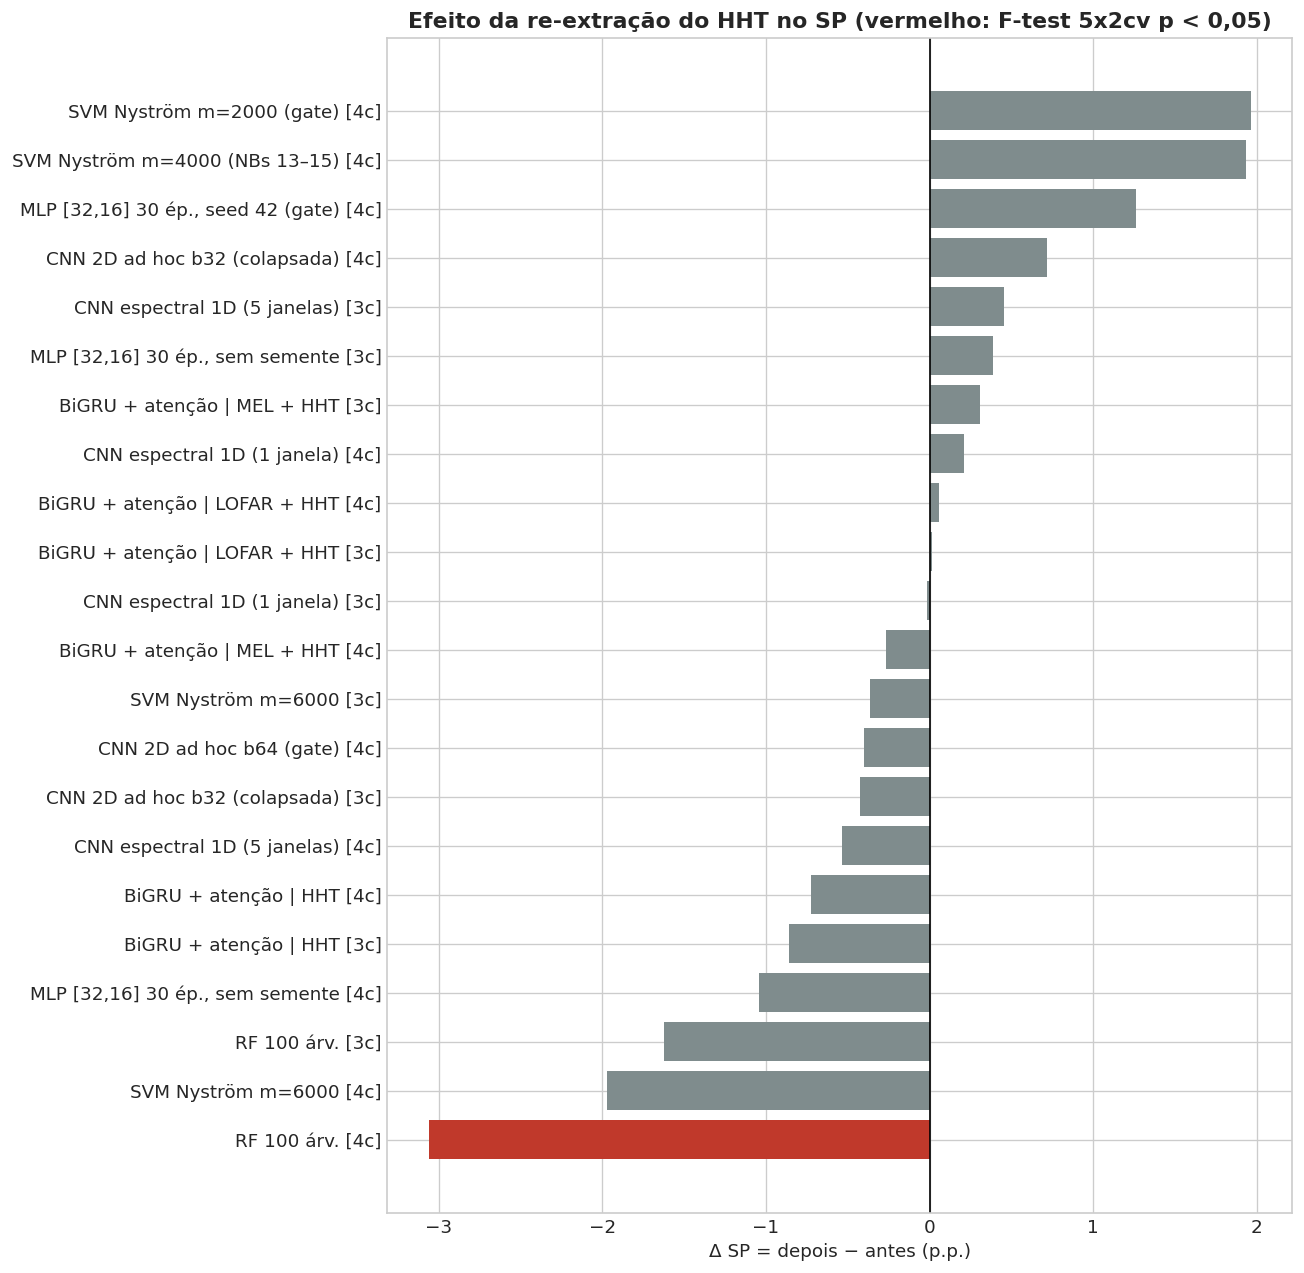

In [6]:
d = cmp.copy()
d['rot'] = d.Modelo + ' [' + d.Modo + ']'
d = d.sort_values('Δ SP')
fig, ax = plt.subplots(figsize=(11, 0.42 * len(d) + 1.5))
cores = ['#c0392b' if p < 0.05 else '#7f8c8d' for p in d['p SP']]
ax.barh(d.rot, d['Δ SP'], color=cores)
ax.axvline(0, color='k', lw=1)
ax.set_xlabel('Δ SP = depois − antes (p.p.)')
ax.set_title('Efeito da re-extração do HHT no SP (vermelho: F-test 5x2cv p < 0,05)', fontweight='bold')
plt.tight_layout()
plt.show()

### 3.1 Leitura
* **12 de 22** combinações modelo × modo têm SP menor depois da correção. Diferenças significativas a 5%: RF 100 árv. [4c]: 60,70 → 57,64 (p = 0,042).
* **Modelos com semente fixa em CPU (a comparação mais limpa):** RF 100 árv. [4c] Δ = -3,06 p.p. (p = 0,042); RF 100 árv. [3c] Δ = -1,62 p.p. (p = 0,360); SVM Nyström m=6000 [4c] Δ = -1,97 p.p. (p = 0,513); SVM Nyström m=6000 [3c] Δ = -0,36 p.p. (p = 0,674); SVM Nyström m=4000 (NBs 13–15) [4c] Δ = 1,93 p.p. (p = 0,651); SVM Nyström m=2000 (gate) [4c] Δ = 1,97 p.p. (p = 0,617).
* **RF HHT**, o melhor modelo HHT antes da correção: 4c 60,70 → **57,64** (p = 0,042); 3c 60,44 → 58,82 (p = 0,360).
* **Melhor modelo só com HHT em 4c:** antes, RF 100 árv. (SP 60,70); depois, CNN espectral 1D (1 janela) (SP 59,52), contra o RF corrigido p = 0,515 (empate estatístico).
* **Fusões com HHT (BiGRU MEL + HHT e LOFAR + HHT):** BiGRU + atenção | MEL + HHT: 64,21 → 63,95 (p = 0,525); BiGRU + atenção | LOFAR + HHT: 63,93 → 63,99 (p = 0,580).
* **Recall de BACKGROUND (4c), onde o confundimento deveria aparecer:** mudança significativa em RF 100 árv.: 66,43 → 58,37% (p = 0,014).

## 4. Efeito no gating (Notebook 26)
A entrada `hht` dos pickles de predições por arquivo foi trocada pelas predições corrigidas e os três experimentos de gating (`scratch/test_competence_gating_all_models.py`, `test_competence_gating_svm.py`, `run_heterogeneous_gating_experiment.py`) foram refeitos. Os baselines MEL, LOFAR e DEMON não mudam; os roteadores são retreinados, porque a competência do especialista HHT mudou.

* Nos 7 sistemas com roteador, o SP muda entre -0,52 e 0,29 p.p.; a maior mudança entre todos os sistemas (incluindo os oráculos) é em RANDOM FOREST 6. Teto do Oráculo Teórico (RANDOM FOREST) (85.64 ± 1.65 → 84.97 ± 1.83).
* H-MoE especializado (MEL:RF, LOFAR:MLP, HHT:RF, DEMON:MLP), o único com SP por fold no pickle: 65,41 → 65,36 (F-test 5×2cv: p = 0,583).
* Nenhum sistema de gating muda mais que 0,52 p.p.; o efeito da correção do HHT no gating é pequeno.

In [7]:
import pickle
PROC = os.path.join(R.ROOT, 'data', 'iara_processed')
PROC_OLD = os.path.join(AUD, 'gating_antes')   # cópia versionada dos pickles de gating antes da correção

def _tabelas(nome):
    """[(família, df antes, df depois)] de um pickle de resultados de gating (antes = backup)."""
    o = pickle.load(open(os.path.join(PROC_OLD, nome + '.pkl'), 'rb'))
    n = pickle.load(open(os.path.join(PROC, nome + '.pkl'), 'rb'))
    return [(k, o[k]['df'], n[k]['df']) for k in o] if 'df' not in o else [('', o['df'], n['df'])]

def _num(s):
    return float(str(s).split('±')[0])

rows = []
for nome in ['results_competence_gating_all_models', 'results_competence_gating_svm', 'results_heterogeneous_gating']:
    for fam, a, b in _tabelas(nome):
        col = a.columns[0]
        for (_, ra), (_, rb) in zip(a.iterrows(), b.iterrows()):
            assert ra[col] == rb[col]
            rows.append({'Pickle': nome.replace('results_', ''), 'Família': fam, 'Sistema': ra[col],
                         'SP antes': ra['SP (%)'], 'SP depois': rb['SP (%)'], 'Δ SP': _num(rb['SP (%)']) - _num(ra['SP (%)']),
                         'Recall SMALL antes': ra['Recall SMALL (%)'], 'Recall SMALL depois': rb['Recall SMALL (%)']})
gate = pd.DataFrame(rows)
gate_sis = gate[gate.Sistema.str.contains('GATED|Gated|H-MoE|Oráculo|Super')]

# H-MoE especializado: único sistema de gating com SP por fold no pickle -> F-test 5x2cv
_ho = pickle.load(open(os.path.join(PROC_OLD, 'results_heterogeneous_gating.pkl'), 'rb'))['res_hetero_expert_fixed']
_hn = pickle.load(open(os.path.join(PROC, 'results_heterogeneous_gating.pkl'), 'rb'))['res_hetero_expert_fixed']
hmoe_old, hmoe_new = np.array([r[0] for r in _ho]), np.array([r[0] for r in _hn])
F_hmoe, p_hmoe = R.f_test_5x2(hmoe_new, hmoe_old)

display(gate_sis)
print(f'H-MoE especializado, SP por fold antes: {hmoe_old.round(2).tolist()}')
print(f'H-MoE especializado, SP por fold depois: {hmoe_new.round(2).tolist()}  (F-test: F = {F_hmoe:.2f}, p = {p_hmoe:.3f})')

,Pickle,Família,Sistema,SP antes,SP depois,Δ SP,Recall SMALL antes,Recall SMALL depois
4,competence_gating_all_models,MLP,5. GATED MLP (RF Competence),65.71 ± 2.29,65.71 ± 2.03,0.00,45.3%,45.3%
5,competence_gating_all_models,MLP,6. Teto do Oráculo Teórico (MLP),86.56 ± 1.11,86.59 ± 1.13,0.03,76.7%,76.6%
10,competence_gating_all_models,RANDOM FOREST,5. GATED RANDOM FOREST (RF Competence),64.56 ± 1.70,64.04 ± 2.18,-0.52,54.9%,55.4%
11,competence_gating_all_models,RANDOM FOREST,6. Teto do Oráculo Teórico (RANDOM FOREST),85.64 ± 1.65,84.97 ± 1.83,-0.67,86.5%,86.4%
16,competence_gating_all_models,CNN 2D,5. GATED CNN 2D (RF Competence),64.00 ± 2.44,64.29 ± 2.18,0.29,40.1%,40.4%
17,competence_gating_all_models,CNN 2D,6. Teto do Oráculo Teórico (CNN 2D),87.26 ± 2.84,87.28 ± 2.63,0.02,73.0%,73.1%
22,competence_gating_svm,,5. GATED SVM (RF Competence Router),64.42 ± 1.93,64.18 ± 2.05,-0.24,46.1%,46.1%
23,competence_gating_svm,,6. Teto do Oráculo Teórico (SVM),88.07 ± 2.05,88.05 ± 1.74,-0.02,85.3%,86.1%
26,heterogeneous_gating,,"3. Gated RF Homogêneo (MEL, LOFAR, HHT, DEMON ...",64.56 ± 1.70,64.04 ± 2.18,-0.52,54.9%,55.4%
27,heterogeneous_gating,,4. H-MoE Automático (Nested CV Model Selection),64.55 ± 1.70,64.40 ± 1.66,-0.15,44.4%,44.7%


H-MoE especializado, SP por fold antes: [65.37, 62.37, 66.26, 66.35, 65.87, 63.09, 65.87, 62.74, 69.03, 67.19]
H-MoE especializado, SP por fold depois: [65.62, 62.89, 67.24, 66.33, 65.58, 63.52, 66.12, 60.97, 68.52, 66.8]  (F-test: F = 0.91, p = 0.583)


## 5. Outros resultados derivados
Notebooks que usam predições HHT e foram regenerados com as predições corrigidas:
* **10** (análise HHT) e **11** (comparação de modelos HHT);
* **13–15** (complementaridade SMALL/MEDIUM/LARGE com o SVM HHT m=4000) e **16–24** (complementaridade por família, MLP/RF/CNN);
* **25** (BiGRU, inclusive as fusões MEL + HHT e LOFAR + HHT);
* **26** (gating): a entrada `hht` de `data/iara_processed/{rf,mlp,svm,cnn}_all_representations_predictions.pkl` foi atualizada com `scratch/update_hht_in_all_representations_pickles.py` e os experimentos de gating foram refeitos;
* **27** (super-oráculo).

Os números HHT de `reports/comparacao_modelos.md` foram recalculados pelo seu script; os relatórios com números digitados à mão (`reports/estudo_viabilidade_hht.md`, `analise_bigru_multiclasse_demon_hht.md`, `analise_bigru_completa_mel_lofar.md`, `implementacao_gating_frontend.md`) receberam uma nota de correção datada com os valores atuais.

## 6. Conclusões
1. **O problema era real:** o cache HHT original misturava duas configurações de EMD, e a configuração estava associada à classe (nenhuma gravação BACKGROUND no grupo extraído com ≥ 100 iterações). Isso viola a premissa de que todas as amostras passam pela mesma extração.
2. **O efeito mensurável ficou concentrado no Random Forest:** SP 4c 60,70 → 57,64 (p = 0,042) e recall de BACKGROUND 66,43 → 58,37% (p = 0,014). É o padrão esperado do confundimento. *Hipótese (não testada):* árvores separam a "assinatura" da extração com cortes em poucos bins, e essa assinatura dizia "não é BACKGROUND".
3. **Nos outros 21 casos a diferença não é significativa a 5%** (|Δ SP| ≤ 1,97 p.p.). Isso não prova que esses modelos não usaram a assinatura, só que o efeito, se existiu, ficou dentro da variação entre folds; nos modelos sem semente a comparação também carrega a aleatoriedade do treino.
4. **Ranking HHT corrigido (4c, só HHT):** o melhor em SP médio passa a ser CNN espectral 1D (1 janela) (SP 59,52); o RF corrigido fica em 57,64 (diferença p = 0,515, empate estatístico).
5. **Gating:** efeito pequeno (≤ 0,52 p.p. nos sistemas com roteador; H-MoE especializado p = 0,583).
6. **Prevenção:** o cache de features deve ser gerado de uma vez, com a configuração gravada junto (como o `config.json` das features LOFAR/MEL do pipeline iara), e conferido por recálculo de uma amostra antes de treinar.